Original number of features: 64

Accuracy without PCA: 97.22 %

Reduced features: 40
Accuracy after PCA: 95.28 %


/Users/ish0nt/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/ish0nt/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/ish0nt/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/ish0nt/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/ish0nt/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_los

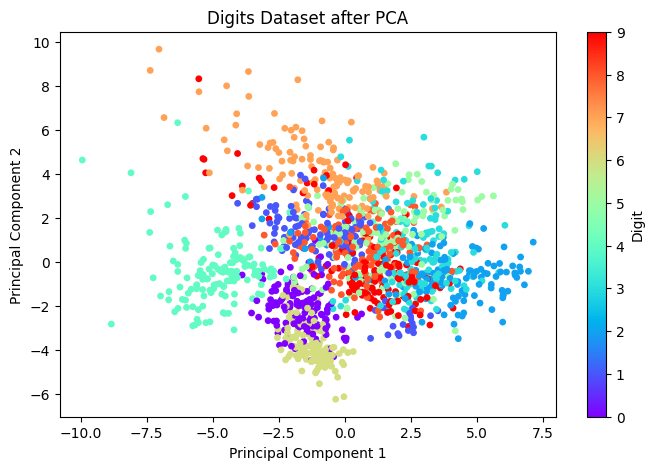

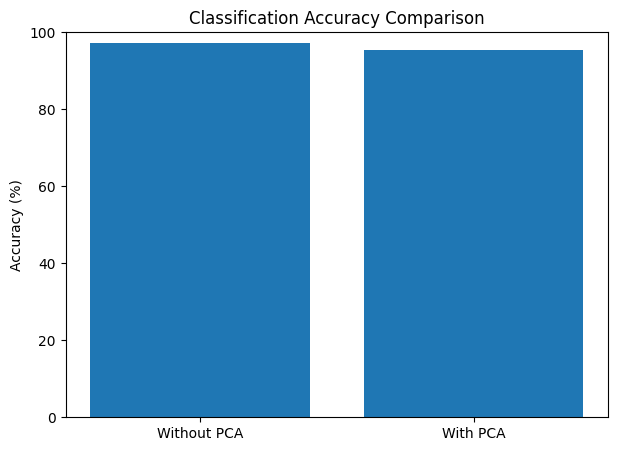


Practical 10 completed successfully!


In [1]:
# PR10: Dimensionality Reduction using PCA

# * TASK 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline


# * TASK 2: Load Digits dataset
data = load_digits()
X = data.data
y = data.target

print("Original number of features:", X.shape[1])


# * TASK 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# * TASK 4: Logistic Regression without PCA
model_original = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000)
)

model_original.fit(X_train, y_train)
y_pred_original = model_original.predict(X_test)

accuracy_original = accuracy_score(y_test, y_pred_original)

print("\nAccuracy without PCA:",
      round(accuracy_original * 100, 2), "%")


# * TASK 5: Apply PCA
pca_model = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95),
    LogisticRegression(max_iter=3000)
)

pca_model.fit(X_train, y_train)
y_pred_pca = pca_model.predict(X_test)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("\nReduced features:",
      pca_model.named_steps["pca"].n_components_)

print("Accuracy after PCA:",
      round(accuracy_pca * 100, 2), "%")


# * TASK 6: Visualize reduced dimensions
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y_train,
    cmap="rainbow",
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Digits Dataset after PCA")
plt.colorbar(label="Digit")
plt.show()


# * TASK 7: Compare classification accuracy
plt.figure(figsize=(7, 5))

plt.bar(
    ["Without PCA", "With PCA"],
    [accuracy_original * 100, accuracy_pca * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("Classification Accuracy Comparison")
plt.ylim(0, 100)
plt.show()


# * TASK 8: Completion
print("\nPractical 10 completed successfully!")